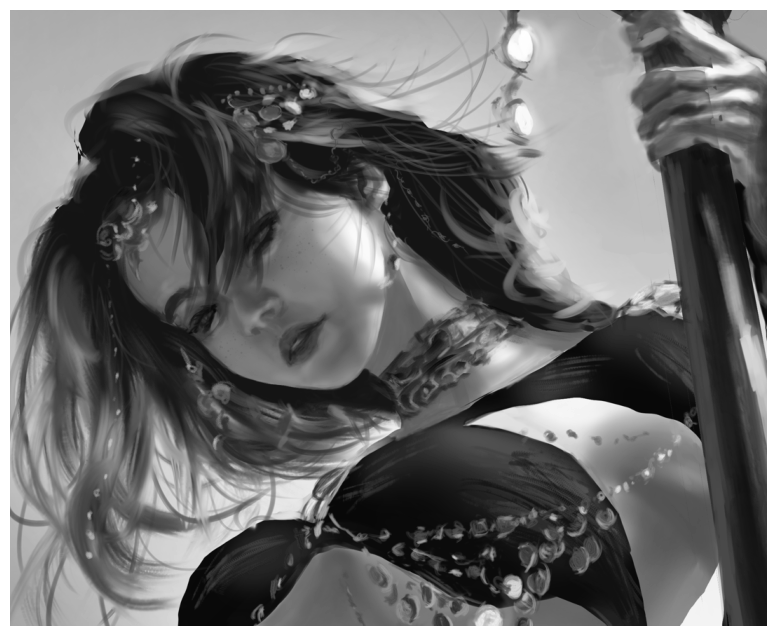

In [3]:
from matplotlib.image import imread
import matplotlib.pyplot as plt
import numpy as np
import os 
plt.rcParams['figure.figsize'] = [16, 8]

path = 'wlop_study_expanded.png'
A = imread(path)
X = np.mean(A, -1); #convert RGB to greyscale

img = plt.imshow(X)
img.set_cmap('grey')
plt.axis('off')
plt.show()

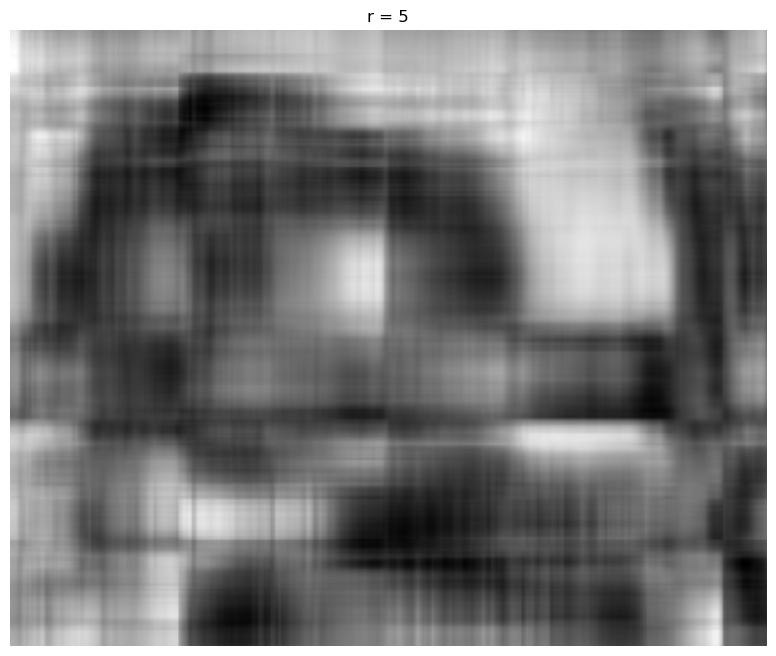

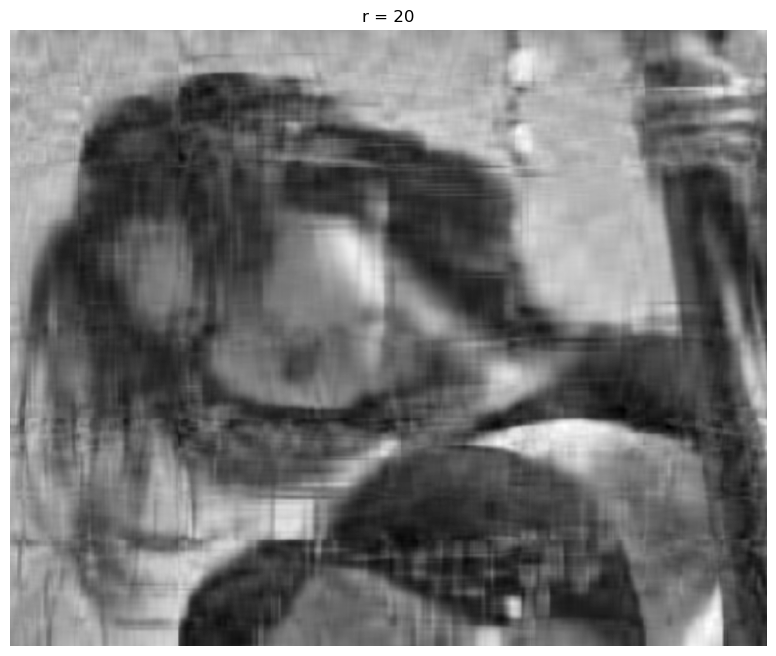

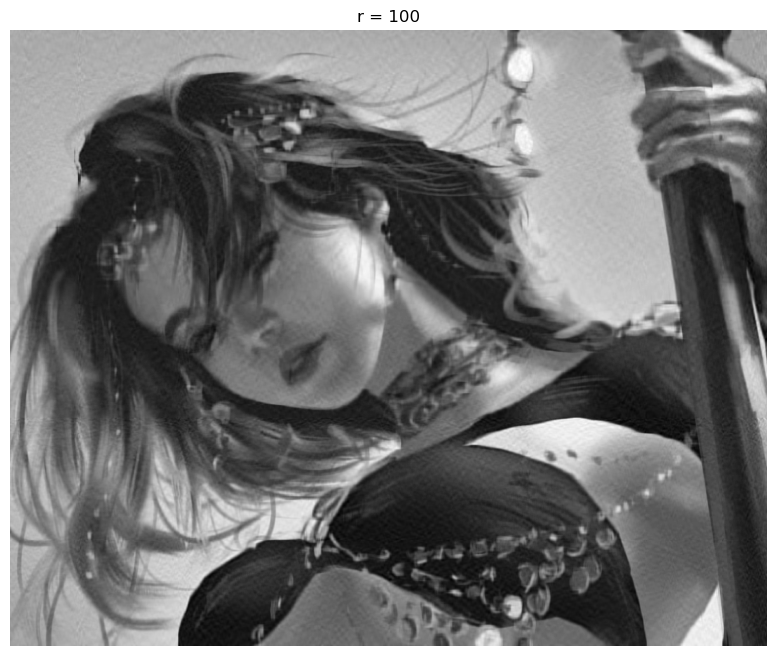

In [4]:
U, S, VT = np.linalg.svd(X, full_matrices=False)
S = np.diag(S)

j = 0
for r in (5, 20, 100):
    #Construct approximate image
    Xapprox = U[:,:r] @ S[:r,:r] @ VT[:r,:]
    plt.figure(j+1)
    j += 1
    img = plt.imshow(Xapprox)
    img.set_cmap('gray')
    plt.axis("off")
    plt.title('r = ' + str(r))
    plt.show()

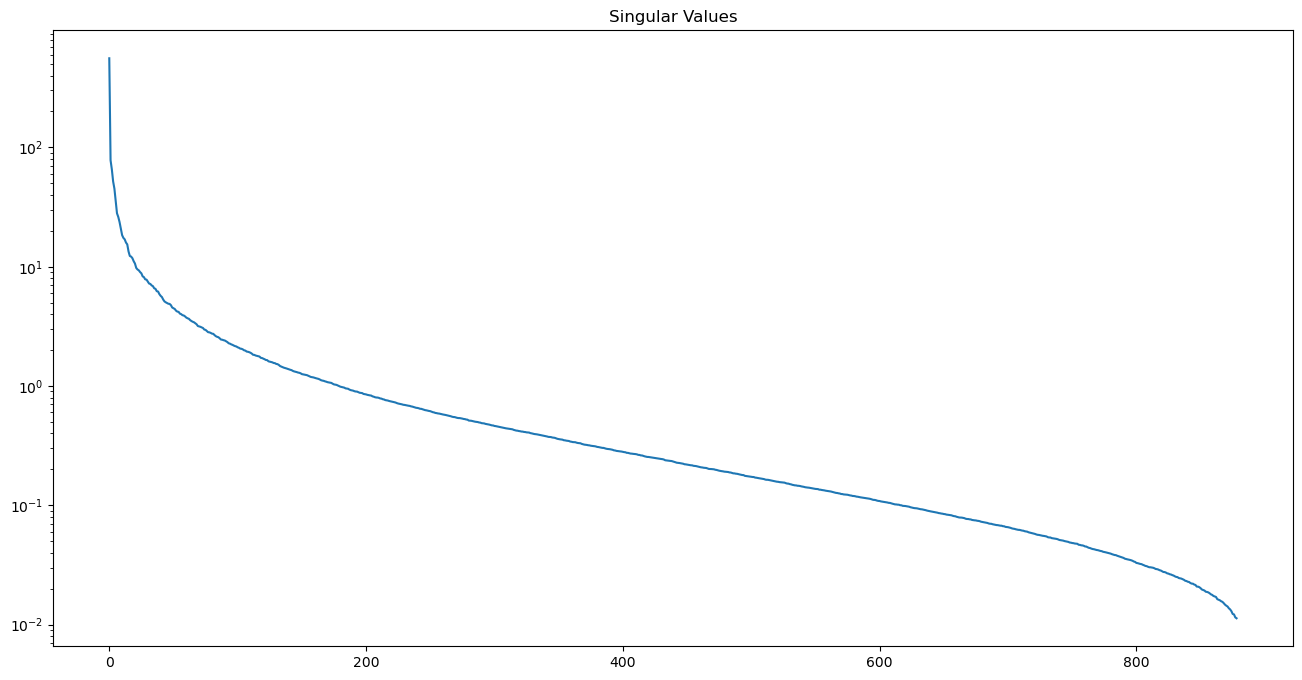

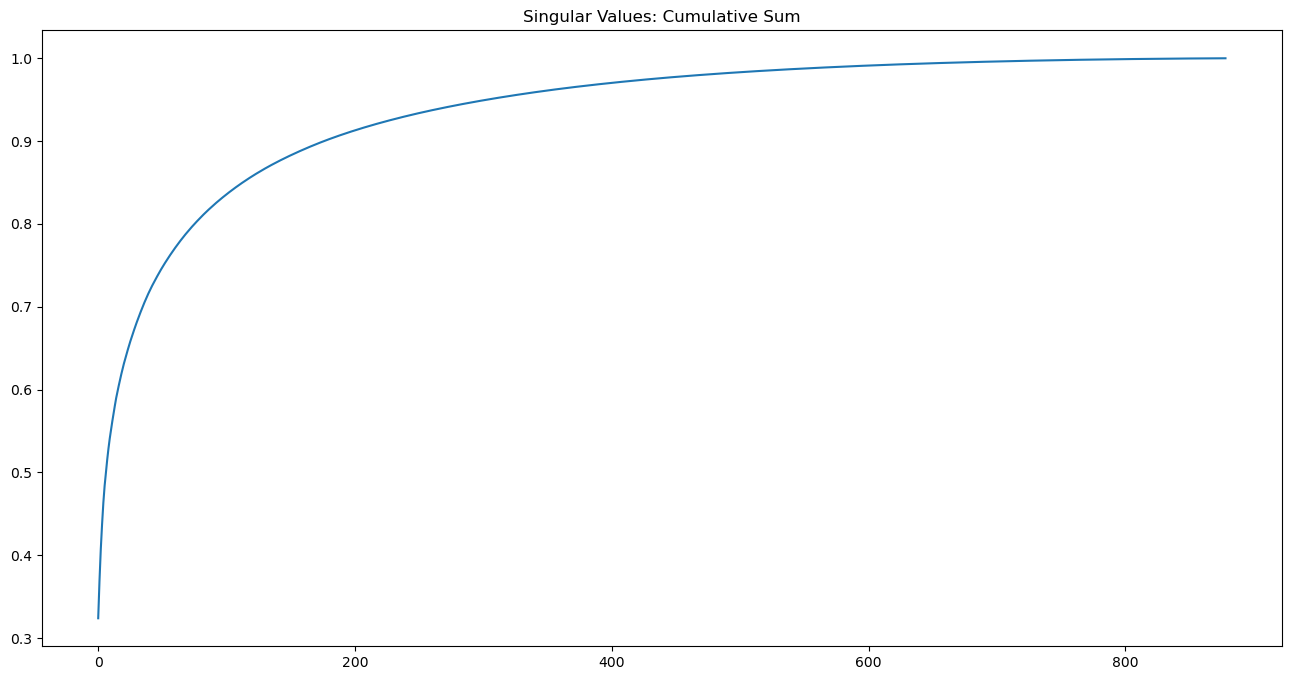

In [5]:
plt.figure(1)
plt.semilogy(np.diag(S))
plt.title('Singular Values')
plt.show()

plt.figure(2)
plt.plot(np.cumsum(np.diag(S)/np.sum(np.diag(S))))
plt.title('Singular Values: Cumulative Sum')
plt.show()

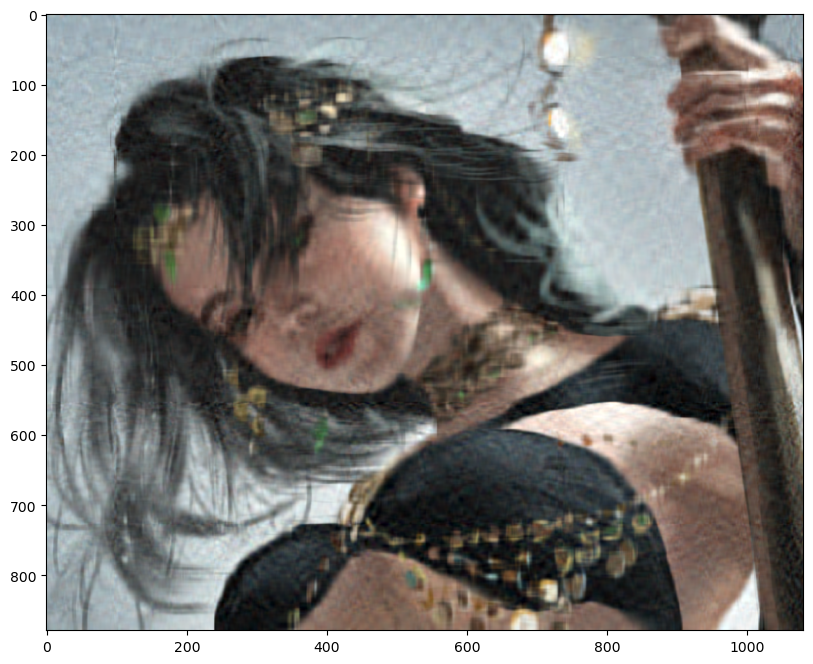

In [20]:
from PIL import Image

# 1. Load the image and convert to float numpy array
img = Image.open(path)
img_array = np.array(img, dtype=float)

# 2. Extract individual R, G, B channels
R = img_array[:, :, 0]
G = img_array[:, :, 1]
B = img_array[:, :, 2]

# Define compression rank (lower k = higher compression = lower quality)
k = 50


def compress_channel(channel, rank):
  # Compute SVD (full_matrices=False saves memory)
  U, S, Vt = np.linalg.svd(channel, full_matrices=False)

  # Reconstruct using only the top 'rank' components
  compressed_channel = U[:, :rank] @ np.diag(S[:rank]) @ Vt[:rank, :]
  return compressed_channel


# 3. Apply SVD compression to each channel
R_compressed = compress_channel(R, k)
G_compressed = compress_channel(G, k)
B_compressed = compress_channel(B, k)

# 4. Merge channels, clip values to standard 0-255 range, and convert back to uint8
compressed_img_array = np.stack(
    (R_compressed, G_compressed, B_compressed), axis=2
)
compressed_img_array = np.clip(compressed_img_array, 0, 255).astype(np.uint8)

# 5. Show the final image
output_img = Image.fromarray(compressed_img_array)
plt.imshow(output_img)
